In [1]:
from __future__ import division
from IPython.display import display
from datetime import datetime
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from my_code.utils import show_videos
from my_code.plotting import plot_channel_stats, plot_compressed_channel_stats, plot_sentiment_series
%matplotlib inline
channels = pd.read_csv('channels.csv')
topics = pd.read_csv('topics.csv')

from my_code.youtube_api import download_channels_videos
download_channels_videos(channels)

from my_code.youtube_api import merge_channel_videos
merge_channel_videos(channels)
from my_code.utils import create_topic_columns
videos = pd.read_csv('videos-MERGED.csv')
create_topic_columns(videos, topics)
videos.to_csv('videos.csv', index=False, encoding='utf-8')
from my_code.language_api import download_sentiments
download_sentiments(videos)

Generated file: videos-cbs-news.csv


c:\Users\YUVRAJ\OneDrive\Desktop\myproject\old_env\my_code\youtube_api.py:75: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  videos['description'].fillna('', inplace=True)


Channel videos merged into videos-MERGED.csv


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\YUVRAJ\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Start processing 8000 videos...
Finished processing 8000 videos.


In [2]:
global all_videos
all_videos = pd.read_csv('videos.csv', parse_dates=['published_at'])
all_videos.head(3)
num_relevant = all_videos.relevant.sum()
num_total = all_videos.shape[0]
print ('Number of relevant videos: %s' % num_relevant)
print ('Total number of videos: %s' % num_total)
print ('Percentage of relevant videos: %0.2f%%' % (100*num_relevant/num_total))

Number of relevant videos: 2238
Total number of videos: 8000
Percentage of relevant videos: 27.98%


In [3]:
channel_stats = pd.DataFrame({
    'relevant': all_videos.groupby('channel').relevant.sum().astype(int),
    'total': all_videos.groupby('channel').size()
})
channel_stats['percentage_relevant'] = (100*channel_stats.relevant/channel_stats.total).round(2)
channel_stats.sort_values('percentage_relevant', ascending=False)

,relevant,total,percentage_relevant
channel,,,
MSNBC,1006,2000,50.3
CBS News,428,2000,21.4
Fox News,406,2000,20.3
CNN,398,2000,19.9


In [4]:
absolutes = all_videos.groupby('channel')[topics.slug].sum().astype(int)
display(absolutes)

,obama,clinton,trump,democrats,republicans,liberals,conservatives
channel,,,,,,,
CBS News,7,0,368,31,57,0,3
CNN,5,0,370,14,22,0,0
Fox News,9,4,359,22,18,1,1
MSNBC,11,1,930,46,83,0,1


In [5]:
totals = all_videos.groupby('channel').size()
relatives = 100 * absolutes.divide(totals, axis=0)
display(relatives)

,obama,clinton,trump,democrats,republicans,liberals,conservatives
channel,,,,,,,
CBS News,0.35,0.00,18.40,1.55,2.85,0.00,0.15
CNN,0.25,0.00,18.50,0.70,1.10,0.00,0.00
Fox News,0.45,0.20,17.95,1.10,0.90,0.05,0.05
MSNBC,0.55,0.05,46.50,2.30,4.15,0.00,0.05


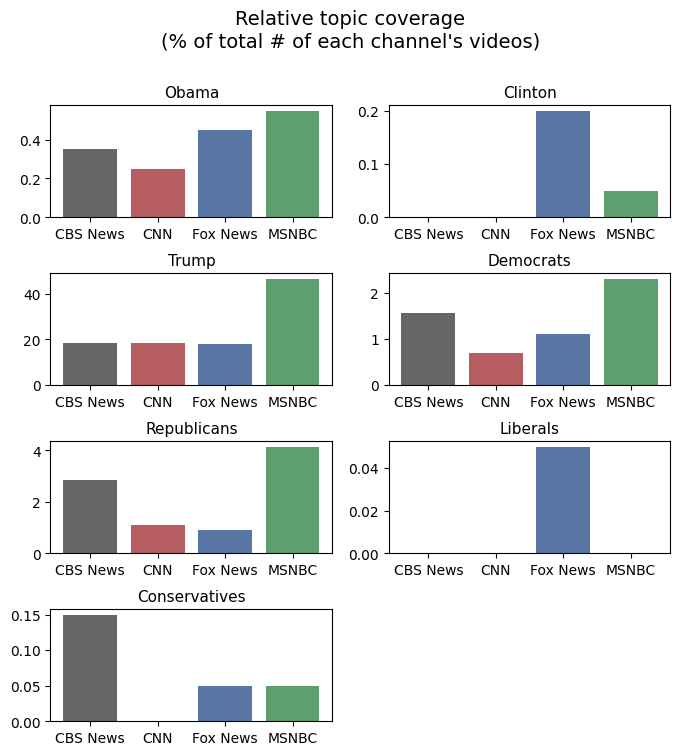

In [6]:
plot_channel_stats(relatives, topics, channels, title='Relative topic coverage\n(% of total # of each channel\'s videos)')

In [7]:
sentiments = pd.read_csv('sentiments.csv')
sentiments[['youtube_id', 'sentiment_score']].head()

,youtube_id,sentiment_score
0,Dqk2emPIavs,0.0000
1,erx0kRpM3l8,0.1779
2,XXGYFLsklfU,-0.6515
3,vm3i1FGlgVc,0.0000
4,bCZfakfUJrA,0.0000


In [8]:
videos = all_videos[all_videos.relevant].merge(sentiments, on='youtube_id')
videos.sort_values('sentiment_score')[['channel', 'title', 'sentiment_score', 'youtube_id']].head(4)

,channel,title,sentiment_score,youtube_id
2065,CBS News,"Trump ties Iran war to 9/11 attacks, war on te...",-0.9337,0w9JvRssS0E
1244,MSNBC,"'Wouldn't vote for him again, NO WAY IN HELL!'...",-0.9128,YdmeoTXVTLM
893,MSNBC,Trump’s LOSING: Why Trump’s 'all-out ASSAULT o...,-0.9035,l4ydwd5SoXg
1998,CBS News,Trump to address U.N. amid tensions with allie...,-0.8885,JmakE0GHl8g


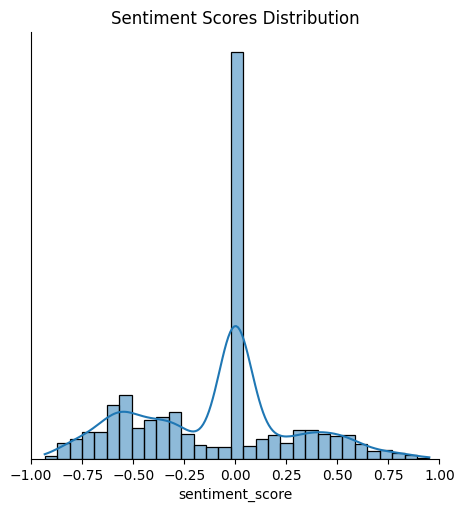

In [9]:
sns.displot(videos.sentiment_score, kde=True)
plt.title('Sentiment Scores Distribution')
plt.gca().get_yaxis().set_visible(False)
plt.xlim(-1, 1)
plt.show()


C:\Users\YUVRAJ\AppData\Local\Temp\ipykernel_15072\3738572784.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores = scores.fillna(0)


Topic,obama,clinton,trump,democrats,republicans,liberals,conservatives
Channel,,,,,,,
CBS News,0.017514,0.0000,-0.058581,0.093239,0.052935,0.0000,-0.098667
CNN,0.147940,0.0000,-0.089663,-0.090179,-0.034791,0.0000,0.000000
Fox News,-0.250200,0.0733,-0.067392,-0.035655,0.149328,-0.4648,0.499500
MSNBC,-0.171845,0.0000,-0.150555,0.021515,-0.141759,0.0000,-0.085700


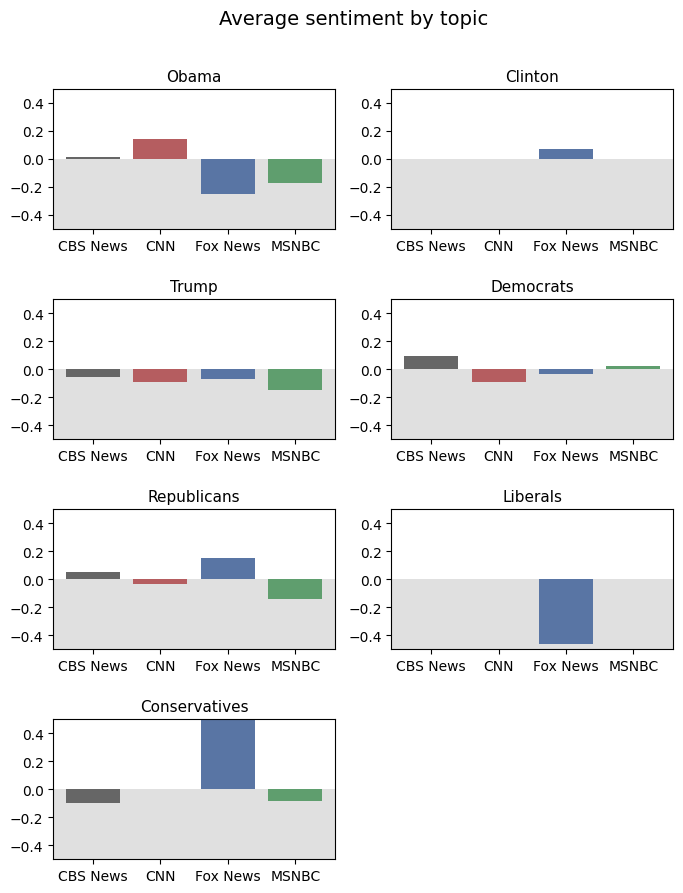

In [10]:
scores = pd.DataFrame(
    index=channels.sort_values('title').title,
    columns=topics.slug
)
for channel, group in videos.groupby('channel'):
    for topic in topics.slug:
        topic_data = group[group[topic]].sentiment_score
        if not topic_data.empty:
            scores.loc[channel, topic] = np.nanmean(topic_data)
        else:
            scores.loc[channel, topic] = np.nan 
scores = scores.rename_axis('Channel', axis=0)
scores = scores.rename_axis('Topic', axis=1)
scores = scores.fillna(0)
display(scores)
plot_channel_stats(scores,topics,channels,fig_height=10,y_center=True,title='Average sentiment by topic')


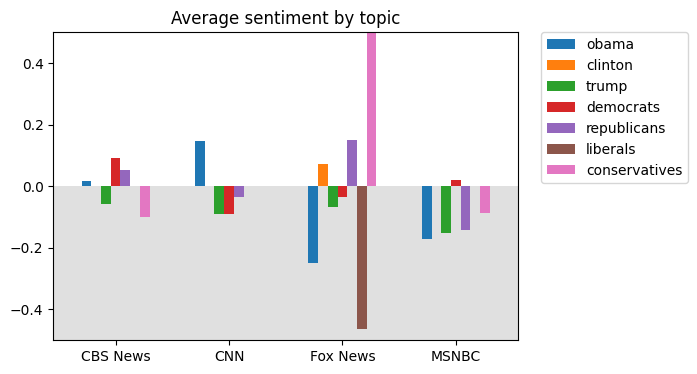

In [11]:
scores = scores.apply(pd.to_numeric, errors='coerce') 
scores = scores.fillna(0)                         
plot_compressed_channel_stats(scores, y_center=True, title='Average sentiment by topic')

In [15]:
from scipy import stats

# Trump videos only, one list of sentiment scores per channel
trump = videos[videos['trump']]
groups = {ch: g['sentiment_score'].values for ch, g in trump.groupby('channel')}

msnbc = groups['MSNBC']
others = np.concatenate([v for ch, v in groups.items() if ch != 'MSNBC'])  # CBS + CNN + Fox

# Average sentiment per group
print(f"MSNBC mean: {msnbc.mean():.3f}   Others mean: {others.mean():.3f}\n")

# Test 1: Kruskal-Wallis -> do the 4 channels differ at all?
h, p = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis: H = {h:.2f}, p = {p:.2e}")
print("-> p < 0.05: at least one channel is different\n" if p < 0.05 else "-> no clear difference\n")

# Test 2: Mann-Whitney U -> is MSNBC different from the others?
u, p = stats.mannwhitneyu(msnbc, others, alternative='two-sided')
prob = u / (len(msnbc) * len(others))   # chance a random MSNBC video scores higher (50% = no difference)
print(f"Mann-Whitney U: U = {u:.0f}, p = {p:.2e}")
print(f"-> A random MSNBC video scores higher only {prob:.1%} of the time (50% = no difference)")
print("-> p < 0.001: the gap is real, but small" if p < 0.001 else "-> no clear difference")

MSNBC mean: -0.151   Others mean: -0.072

Kruskal-Wallis: H = 22.91, p = 4.21e-05
-> p < 0.05: at least one channel is different

Mann-Whitney U: U = 451460, p = 4.70e-06
-> A random MSNBC video scores higher only 44.3% of the time (50% = no difference)
-> p < 0.001: the gap is real, but small
